In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import scienceplots
from scipy.integrate import odeint
from multiprocessing import Pool
from tqdm import tqdm
from scipy.io import loadmat
import pandas as pd
from scipy import integrate
from scipy.optimize import fsolve
import operator
import pickle
import hdf5storage
from itertools import permutations
import itertools
import random
import powerlaw
import networkx as nx
import xgi
from matplotlib.patches import FancyArrowPatch

import sys;
sys.path.append("/home/qinjiajie/jupyter_code/2-Tipping_point/High_order_dynamic")

from utils import *
import utils
from importlib import reload
reload(utils)

<module 'utils' from '/home/qinjiajie/jupyter_code/2-Tipping_point/High_order_dynamic/utils.py'>

In [2]:
def f2_threshold(paras1,paras2,g1, f):
    alpha,beta,gamma,alpha1,beta1,gamma1,rho = paras1
    # d1dt = f*x[0] + g1*alpha*(1-beta*x[0])*gamma*x[0] + g2*alpha1*(1-beta1*x[1])*gamma1*x[1]*rho*x[1]
    
    alpha_2,beta_2,gamma_2,alpha1_2,beta1_2,gamma1_2,rho_2 = paras2

    g2_up = f*(f-g1*alpha*gamma**a)
    g2_lower = (f-g1*alpha*gamma**a)*beta1_2*(2*rho_2)**a + g1*alpha_2*beta*gamma_2**a * (2*rho)**a
    g2 = g2_up/g2_lower
    return g2

In [3]:
directory_path = './result_0909/'
result_large_2d = hdf5storage.loadmat(directory_path + 'boundary_collapse.mat')
theory_collapse_tipping = result_large_2d['boundary_collapse']

In [4]:
directory_path = './result_0909/'
result_large = hdf5storage.loadmat(directory_path + 'boundary_collapse_origin.mat')
true_collapse_tipping = result_large['u1']

In [7]:
f = 7
g1 = 0.5
a = 1
h = 1

directory_path = './result_0909/'
zz = hdf5storage.loadmat(directory_path + 'zz.mat')
zz = zz['zz']

In [8]:
f2_crit = f2_threshold(zz[0][:7],zz[1][:7],g1,f)

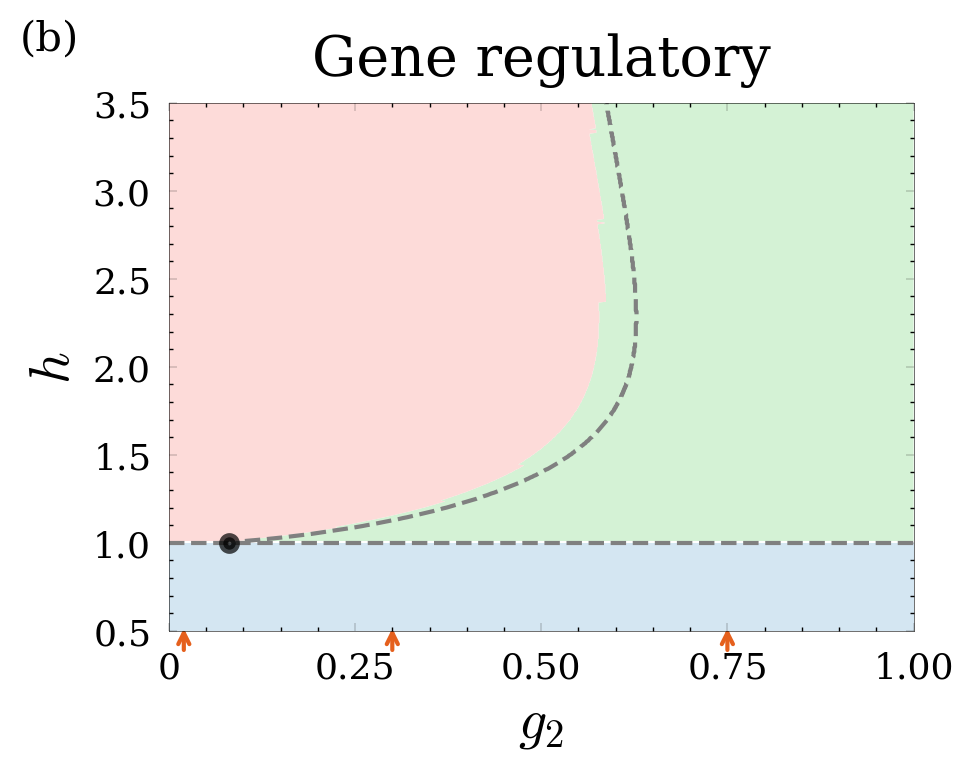

In [9]:
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import FuncFormatter
with plt.style.context(['science', 'no-latex']):
    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(5, 4))
    bwith = 0.2  # 边框宽度设置为2
    ax.spines['bottom'].set_linewidth(bwith)
    ax.spines['left'].set_linewidth(bwith)
    ax.spines['top'].set_linewidth(bwith)
    ax.spines['right'].set_linewidth(bwith)

    ax.fill_betweenx([0,1],
                    [0,0],
                    [1,1],
                    facecolor='#D4E6F2',label='Survival')
    
    ax.fill_betweenx(true_collapse_tipping[:,0],
                    true_collapse_tipping[:,1],
                     1*np.ones(len(true_collapse_tipping[:,1])),
                    facecolor='#D4F2D5',label='Sensitivity')

    ax.fill_betweenx(true_collapse_tipping[:,0],
                    true_collapse_tipping[:,1],
                    0*np.ones(len(true_collapse_tipping[:,1])),
                    facecolor='#FDDBD9',label='Collapse')
    ax.axhline(y=1,label='Stability',c='#808080',linewidth =1.5,linestyle='dashed') #d170a8
    ax.plot(theory_collapse_tipping[:,1],theory_collapse_tipping[:,0],label='Two-Dims',c='#808080',linewidth =1.5,linestyle='dashed')
    ax.scatter(f2_crit,1, zorder=10, marker='o', s=20, facecolors='k', edgecolors='k', linewidths=3, alpha=0.7)

    ax.set_ylim([0.5,3.5])
    ax.set_xlim([0,1])
    ax.set_xlabel(r'$g_2$',fontsize=20)
    ax.set_ylabel(r'$h$',fontsize=20)
    ax.set_title('Gene regulatory',fontsize=20, pad=10)
    ax.tick_params(width=0.1)

    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.text(-0.2,1.1,'(b)',fontsize=15,transform=ax.transAxes)
    ax.tick_params(axis='both', labelsize=13, pad=7)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: '0' if abs(x) < 1e-12 else f'{x:.2f}'))
    for x0 in [0.02, 0.3, 0.75]:
        arrow = FancyArrowPatch(
            (x0, -0.047),   # 起点
            (x0, 0.015),    # 终点
            transform=ax.get_xaxis_transform(),
            arrowstyle='->',
            mutation_scale=10,
            linewidth=1.5,
            color='#E5601D',
            clip_on=False
        )
        ax.add_patch(arrow)
plt.tight_layout()
plt.savefig("grn_1017.pdf", format='pdf', dpi=600)
plt.show()